# What predicts the results of the Great British Baking Show?

This short project original started as an assignment for a class I teach (DS2003), but I enjoyed playing around with this data so I wanted to analyze it further!

## About the data
Two datasets: one row per baker per episode (results, technical ranks, and scores for each bake), and one row per episode (UK viewers).

In [1]:
# !pip install pandas matplotlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


HIGHLIGHT, MUTED = "#EE42B2", "#bbbbbb"   # one strong color for the story, grey for context
SCI, SCI_LIGHT = "#3B6E8F", "#A9C3D6"    # muted steel blue (and a light tint) for the scientific figures
SCI_ORANGE = "#D98C3F"                   # muted orange, paired with SCI in Figure 4

# Great British Bake Off: UK viewers per episode, series 1-10 (TidyTuesday, 2022-10-25)
bake = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2022/2022-10-25/ratings.csv",
                   parse_dates=["uk_airdate"])
bake.head()

,series,episode,uk_airdate,viewers_7day,viewers_28day,network_rank,channels_rank,bbc_iplayer_requests,episode_count,us_season,us_airdate
0,1,1,2010-08-17,2.24,7.0,NaN,NaN,NaN,1,NaN,NaN
1,1,2,2010-08-24,3.00,3.0,NaN,NaN,NaN,2,NaN,NaN
2,1,3,2010-08-31,3.00,2.0,NaN,NaN,NaN,3,NaN,NaN
3,1,4,2010-09-07,2.60,4.0,NaN,NaN,NaN,4,NaN,NaN
4,1,5,2010-09-14,3.03,1.0,NaN,NaN,NaN,5,NaN,NaN


In [2]:
# The bakers: one row per baker per episode (github.com/nathangiusti/BakeOff).
# Its Series column uses Netflix numbering: 5-13 = UK series 8-16 (2017-2025), the Channel 4 years
judging = pd.read_csv("https://raw.githubusercontent.com/nathangiusti/BakeOff/main/data_collection/judging/human/data.csv")
judging["bakers"] = judging.groupby(["Series", "Round"])["Contestant"].transform("size")   # bakers left that week
judging["eliminated"] = judging["Eliminated"].fillna(0)                                    # 1 = sent home that week
weeks = judging[judging["bakers"] > 3]                                                     # drop the finals

judging.head()

,Contestant,Series,Round,Signature Bake,Signature Flavor,Signature Looks,Signature Handshake,Tech,First Half Review,Showstopper Bake,Showstopper Flavor,Showstopper Looks,Showstopper Handshake,Second Half Review,Winner,Eliminated,bakers,eliminated
0,Kate,5,1,0,-1,-1,NaN,1,NaN,1,1,0,NaN,NaN,NaN,NaN,12,0.0
1,Peter,5,1,-1,-1,0,NaN,10,NaN,-1,1,-1,NaN,-1.0,NaN,1.0,12,1.0
2,Tom,5,1,-1,0,1,NaN,7,NaN,0,1,-1,NaN,NaN,NaN,NaN,12,0.0
3,Julia,5,1,-1,0,0,NaN,3,NaN,-1,-1,1,NaN,NaN,NaN,NaN,12,0.0
4,Flo,5,1,1,1,1,NaN,9,NaN,1,1,1,NaN,1.0,NaN,NaN,12,0.0


In [3]:
# just get non-NA
judging.loc[~judging['Signature Handshake'].isna()].head()

,Contestant,Series,Round,Signature Bake,Signature Flavor,Signature Looks,Signature Handshake,Tech,First Half Review,Showstopper Bake,Showstopper Flavor,Showstopper Looks,Showstopper Handshake,Second Half Review,Winner,Eliminated,bakers,eliminated
8,Steven,5,1,1,1,1,1.0,6,NaN,1,1,1,NaN,1.0,1.0,NaN,12,0.0
11,Sophie,5,1,1,1,1,1.0,5,NaN,-1,1,1,NaN,1.0,NaN,NaN,12,0.0
36,Liam,5,4,1,1,1,1.0,3,1.0,1,1,1,NaN,1.0,NaN,NaN,9,0.0
45,Yan,5,5,1,1,1,1.0,6,1.0,-1,1,1,NaN,NaN,NaN,NaN,8,0.0
46,Steven,5,5,1,1,1,1.0,5,1.0,-1,1,1,NaN,NaN,NaN,NaN,8,0.0


### About the data: The Great British Bake Off (or "Great British Baking Show" for the US release of the same show)

- If you've never seen the show, it a delight and you should absolutely watch it!
- Each week there is a category (classic episodes are Bread Week, Cake Week, Chocolate Week, Pastry Week, among others, and every once in a while there is a different one-off category like "Free-from Baking Week" or a specific cuisine)
- There are three rounds in each episode: **Signature, Technical, and Showstopper.**
  - The contestants are judges on lots of things, but they tend to fall into three categories: **bake** (how well they actually did making the thing with the right texture), **flavor**, and **looks**. 
  - This data has a +1, 0, or -1 based on manual annotation from what the judges said in the episode. 
  - There is a special "Paul Hollywood **Handshake**" which basically means they made something perfectly and the stricter judge, Paul, gives them a handshake for it

## Part 1: Does the technical decide who goes home?

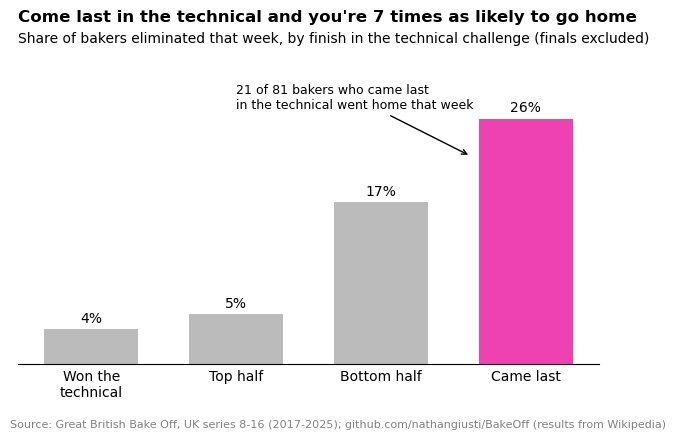

,mean,sum,size
Won the\ntechnical,0.037037,3.0,81
Top half,0.053097,12.0,226
Bottom half,0.171103,45.0,263
Came last,0.259259,21.0,81


In [4]:
# Group each baker by where they finished in that week's technical, relative to how many bakers were left
finish = np.select([weeks["Tech"] == 1, weeks["Tech"] == weeks["bakers"], weeks["Tech"] <= weeks["bakers"] / 2],
                   ["Won the\ntechnical", "Came last", "Top half"], default="Bottom half")
order = ["Won the\ntechnical", "Top half", "Bottom half", "Came last"]
rates = weeks.groupby(finish)["eliminated"].agg(["mean", "sum", "size"]).loc[order]

fig, ax = plt.subplots(figsize=(7, 4.2))

# highlight: only the group the story is about gets color
colors = [HIGHLIGHT if g == "Came last" else MUTED for g in order]
bars = ax.bar(order, rates["mean"], color=colors, width=0.65)

# declutter: no box, no y-axis (the bars are labeled directly), no tick marks
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_yticks([])
ax.tick_params(axis="x", length=0)
ax.set_ylim(0, 0.33)

# direct labels: the value sits on each bar
ax.bar_label(bars, labels=[f"{v:.0%}" for v in rates["mean"]], padding=3, fontsize=10)

# annotate: xy is where the arrow points, xytext is where the words sit (both in data coordinates)
ax.annotate(f"{rates.loc['Came last', 'sum']:.0f} of {rates.loc['Came last', 'size']} bakers who came last\nin the technical went home that week",
            xy=(2.62, 0.22), xytext=(1.0, 0.27),
            arrowprops=dict(arrowstyle="->"), fontsize=9)

# active title + subtitle (the subtitle is in axes coordinates, so it stays put above the plot)
ax.set_title("Come last in the technical and you're 7 times as likely to go home",
             loc="left", fontweight="bold", fontsize=12, pad=22)
ax.text(0, 1.03, "Share of bakers eliminated that week, by finish in the technical challenge (finals excluded)",
        transform=ax.transAxes, fontsize=10)

# Source line, bottom left of the figure
fig.text(0.01, -0.03, "Source: Great British Bake Off, UK series 8-16 (2017-2025); github.com/nathangiusti/BakeOff (results from Wikipedia)",
         fontsize=8, color="grey")
fig.tight_layout()
plt.show()

rates

## Part 2: Does a Hollywood handshake guarantee success?

The lore of the Hollywood Handshake means it is much coveted throughout the episodes. But does it actually relate to who wins each episode, and who wins the season overall?



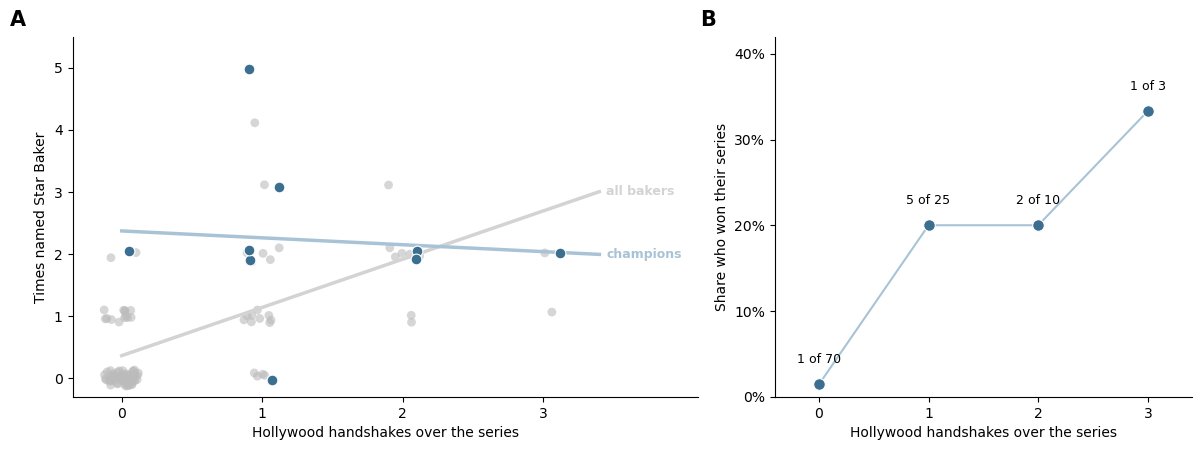

In [5]:
# One row per baker: handshakes over their whole series, and how many times they were Star Baker
judging["handshake"] = ((judging["Signature Handshake"] == 1) | (judging["Showstopper Handshake"] == 1)).astype(int)
judging["star_baker"] = judging["Winner"].fillna(0).where(judging["bakers"] > 3, 0)   # don't count the final

finals = judging[judging["bakers"] == 3]
champions = set(zip(finals.loc[finals["Winner"] == 1, "Series"], finals.loc[finals["Winner"] == 1, "Contestant"]))

per_baker = judging.groupby(["Series", "Contestant"]).agg(handshakes=("handshake", "sum"),
                                                         star_bakers=("star_baker", "sum"),
                                                         weeks_on_show=("Round", "size")).reset_index()
per_baker["champion"] = [(s, c) in champions for s, c in zip(per_baker["Series"], per_baker["Contestant"])]
rng = np.random.default_rng(3)                        # fixed seed, so the jitter is the same every run
#seaborn has a built in stripplot that "jitters" the dots so you can see them all. We'll recreate that here in a different way.
per_baker["x"] = per_baker["handshakes"] + rng.uniform(-0.13, 0.13, len(per_baker))
per_baker["y"] = per_baker["star_bakers"] + rng.uniform(-0.13, 0.13, len(per_baker))
champs = per_baker[per_baker["champion"]]
others = per_baker[~per_baker["champion"]]

# Panel B data: share of bakers who won their series, by number of handshakes
by_hs = per_baker.groupby("handshakes").agg(bakers=("champion", "size"), won=("champion", "sum"))
by_hs["share_won"] = by_hs["won"] / by_hs["bakers"]

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})

# ---- Panel A: every baker; champions in color on top, everyone else grey and see-through
axA.scatter(others["x"], others["y"], s=40, color=MUTED, alpha=0.6, edgecolor="none")
axA.scatter(champs["x"], champs["y"], s=60, color=SCI, edgecolor="white", linewidth=0.8, zorder=3)

# trend lines, fit to the real (un-nudged) values: light grey for all bakers, light blue for the champions only
xs = np.array([0, 3.4])
for data, col, label in [(per_baker, "lightgrey", "all bakers"), (champs, SCI_LIGHT, "champions")]:
    slope, intercept = np.polyfit(data["handshakes"], data["star_bakers"], 1)
    axA.plot(xs, intercept + slope * xs, color=col, lw=2.5, zorder=2)
    axA.text(3.45, intercept + slope * 3.4, label, color=col, fontsize=9, fontweight="bold", va="center")

axA.spines[["top", "right"]].set_visible(False)
axA.set_xlim(-0.35, 4.1)
axA.set_ylim(-0.3, 5.5)
axA.set_xticks([0, 1, 2, 3])              # whole numbers only: the jitter is not real data
axA.set_yticks([0, 1, 2, 3, 4, 5])
axA.set_xlabel("Hollywood handshakes over the series")
axA.set_ylabel("Times named Star Baker")

# annotate (with restraint): the two bakers who break the pattern
def spot(name, series):
    row = per_baker[(per_baker["Contestant"] == name) & (per_baker["Series"] == series)].iloc[0]
    return (row["x"], row["y"])

# ---- Panel B: one dot per handshake count, labeled with the counts behind each share
axB.plot(by_hs.index, by_hs["share_won"], color=SCI_LIGHT, lw=1.5, zorder=1)
axB.scatter(by_hs.index, by_hs["share_won"], s=70, color=SCI, edgecolor="white", linewidth=0.8, zorder=2)
for h, row in by_hs.iterrows():
    axB.text(h, row["share_won"] + 0.025, f"{row['won']:.0f} of {row['bakers']:.0f}", ha="center", fontsize=9)
axB.spines[["top", "right"]].set_visible(False)
axB.set_xticks([0, 1, 2, 3])
axB.set_xlim(-0.4, 3.4)
axB.set_ylim(0, 0.42)
axB.set_yticks([0, 0.1, 0.2, 0.3, 0.4], ["0%", "10%", "20%", "30%", "40%"])
axB.set_xlabel("Hollywood handshakes over the series")
axB.set_ylabel("Share who won their series")

# ---- Panel letters, in axes coordinates so they sit at each panel's top-left corner
axA.text(-0.1, 1.03, "A", transform=axA.transAxes, fontsize=15, fontweight="bold")
axB.text(-0.18, 1.03, "B", transform=axB.transAxes, fontsize=15, fontweight="bold")

fig.tight_layout()  
plt.show()

**Figure 2. Bakers who earn more Hollywood handshakes are named Star Baker more often and are more likely to win their series.**
**(A)** Handshakes (signature or showstopper bake) and Star Baker wins over each baker's series. Each dot is one baker (n = 108), nudged slightly at random so overlapping bakers are visible; series champions in blue. Lines are least-squares fits to the un-nudged values for all bakers (grey, slope +0.78) and for the 9 champions only (blue, slope −0.11). Star Baker in the final is not counted. **(B)** Share of bakers who won their series, by number of handshakes; labels give winners out of bakers.
Data: *The Great British Bake Off*, UK series 8–16 (2017–2025), compiled by N. Giusti (github.com/nathangiusti/BakeOff); weekly results from Wikipedia.

### Who is in each group?
Here is the data behind panel B, with how long each group lasted on the show.

In [6]:
per_baker.groupby("handshakes").agg(bakers=("champion", "size"),
                                    won_series=("champion", "sum"),
                                    avg_weeks_on_show=("weeks_on_show", "mean")).round(1)

,bakers,won_series,avg_weeks_on_show
handshakes,,,
0,70,1,4.8
1,25,5,8.6
2,10,2,9.7
3,3,1,8.7


Longer on show = more chances to get a handshake. If we regress out this relationship, is there still a relationship between number of handshakes and probability of winning the series?

In [7]:
import statsmodels.formula.api as smf

# Step 1: how many handshakes would we expect from time on the show alone?
time_fit = smf.ols("handshakes ~ weeks_on_show", data=per_baker).fit()
per_baker["extra_handshakes"] = time_fit.resid          # handshakes above (+) or below (-) what time on the show predicts
print(f"Each extra week on the show = {time_fit.params['weeks_on_show']:.2f} more handshakes "
      f"(R² = {time_fit.rsquared:.2f})")

# Step 2: do the leftover ("extra") handshakes predict winning the series?
per_baker["won"] = per_baker["champion"].astype(int)
raw_fit = smf.logit("won ~ handshakes", data=per_baker).fit(disp=0)
resid_fit = smf.logit("won ~ extra_handshakes", data=per_baker).fit(disp=0)

# Step 3: the cleanest comparison: finalists only, who were all on the show for all 10 weeks
finalists = per_baker[per_baker[["Series", "Contestant"]].apply(tuple, axis=1).isin(set(zip(finals["Series"], finals["Contestant"])))]
final_fit = smf.logit("won ~ handshakes", data=finalists).fit(disp=0)

summary = pd.DataFrame({
    "model": ["all bakers: won ~ handshakes", "all bakers: won ~ extra handshakes", "finalists only: won ~ handshakes"],
    "n": [len(per_baker), len(per_baker), len(finalists)],
    "odds ratio per handshake": [np.exp(m.params.iloc[1]) for m in (raw_fit, resid_fit, final_fit)],
    "p-value": [m.pvalues.iloc[1] for m in (raw_fit, resid_fit, final_fit)],
}).round(3)
summary

Each extra week on the show = 0.15 more handshakes (R² = 0.34)


,model,n,odds ratio per handshake,p-value
0,all bakers: won ~ handshakes,108,3.000,0.003
1,all bakers: won ~ extra handshakes,108,1.921,0.170
2,finalists only: won ~ handshakes,27,1.313,0.549


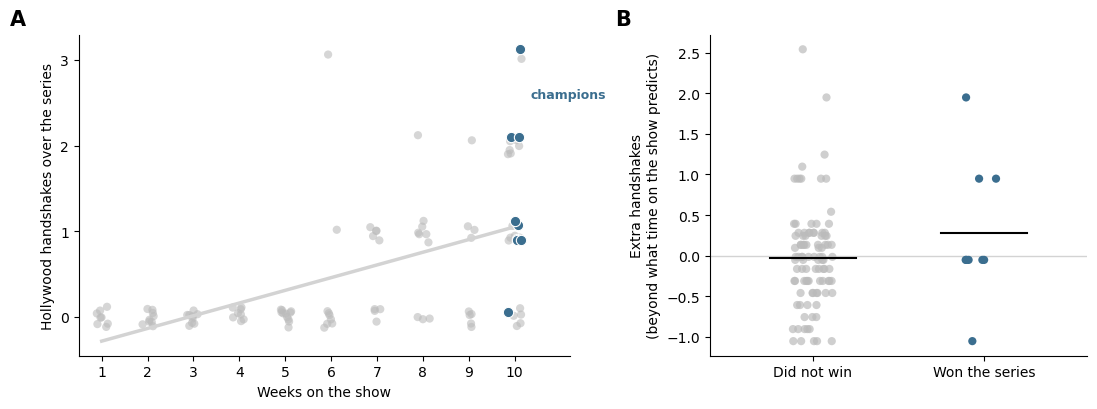

In [8]:
fig, (axA, axB) = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})

# ---- Panel A: handshakes vs. weeks on the show, with the time-on-show fit we regress out
jx = rng.uniform(-0.15, 0.15, len(per_baker))
axA.scatter(others["weeks_on_show"] + jx[~per_baker["champion"]], others["x"],
            s=35, color=MUTED, alpha=0.6, edgecolor="none")
axA.scatter(champs["weeks_on_show"] + jx[per_baker["champion"]], champs["x"],
            s=55, color=SCI, edgecolor="white", linewidth=0.8, zorder=3)
xs = np.array([1, 10])
axA.plot(xs, time_fit.params["Intercept"] + time_fit.params["weeks_on_show"] * xs, color="lightgrey", lw=2.5, zorder=2)
axA.set_xticks(range(1, 11))
axA.set_yticks([0, 1, 2, 3])
axA.set_xlabel("Weeks on the show")
axA.set_ylabel("Hollywood handshakes over the series")
axA.set_xlim(0.5, 11.2)
axA.text(10.35, 2.6, "champions", color=SCI, fontsize=9, fontweight="bold", va="center")
axA.spines[["top", "right"]].set_visible(False)

# ---- Panel B: what's left after removing time on the show, champions vs. everyone else
for k, (grp, col) in enumerate([(per_baker[~per_baker["champion"]], MUTED), (per_baker[per_baker["champion"]], SCI)]):
    axB.scatter(k + rng.uniform(-0.12, 0.12, len(grp)), grp["extra_handshakes"], s=35, color=col,
                alpha=0.7 if k == 0 else 1, edgecolor="none")
    axB.plot([k - 0.25, k + 0.25], [grp["extra_handshakes"].mean()] * 2, color="black", lw=1.5)
axB.axhline(0, color="lightgrey", lw=1, zorder=0)
axB.set_xticks([0, 1], ["Did not win", "Won the series"])
axB.set_xlim(-0.6, 1.6)
axB.set_ylabel("Extra handshakes\n(beyond what time on the show predicts)")
axB.spines[["top", "right"]].set_visible(False)

axA.text(-0.14, 1.03, "A", transform=axA.transAxes, fontsize=15, fontweight="bold")
axB.text(-0.25, 1.03, "B", transform=axB.transAxes, fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**What this shows.** Time on the show explains about a third of the variation in handshakes (each extra week ≈ 0.15 more handshakes). After removing that, champions still average a few more "extra" handshakes than everyone else (panel B), but the difference is small and not statistically reliable (odds ratio ≈ 1.9 per extra handshake, p ≈ 0.17, with only 9 champions). Among the 27 finalists, who all lasted 10 weeks, handshakes barely predict who wins (p ≈ 0.55): the 2024 champion had none, while two finalists with three handshakes lost. So most of the raw handshake–winning link is time on the show.

One caveat: weeks on the show is not just "chances." Lasting longer is itself a result of baking well, so regressing it out also removes some real skill signal. That makes this a conservative test, and with 9 series the data can't rule out a modest effect.

## Part 3. Predicting who goes home based on judges' comments for the Signature and the Showstopper

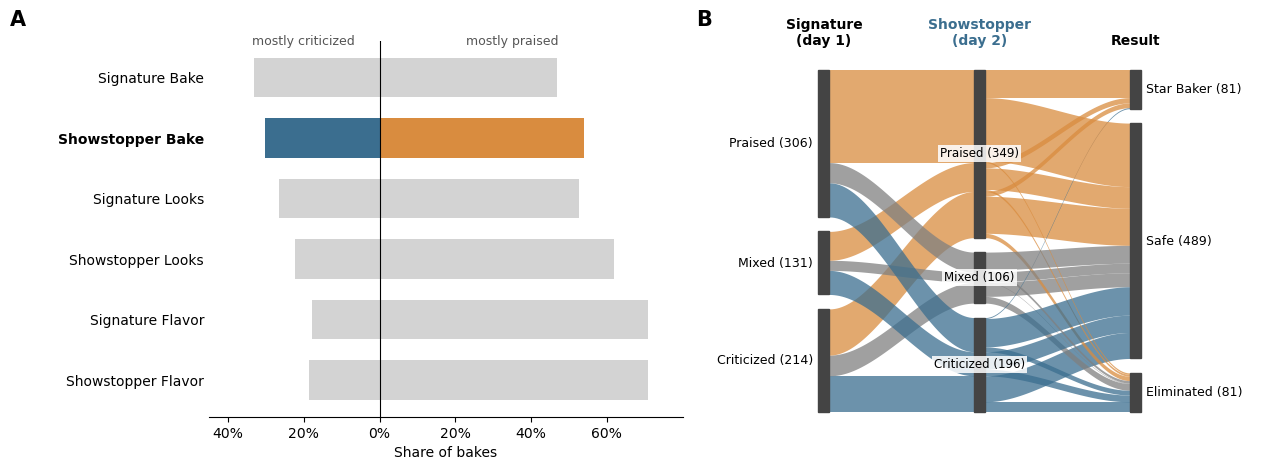

In [9]:
# ---- Panel A data: share of each bake judged mostly negative / mostly positive
parts = ["Signature Bake", "Showstopper Bake", "Signature Looks",
         "Showstopper Looks", "Signature Flavor", "Showstopper Flavor"]
neg = [(judging[p] == -1).mean() for p in parts]
pos = [(judging[p] == 1).mean() for p in parts]
rows = list(range(len(parts)))[::-1]               # first part at the top

# ---- Panel B data: one row per baker-week: signature verdict -> showstopper verdict -> result (finals excluded)
verdict = {-1: "Criticized", 0: "Mixed", 1: "Praised"}
flow = pd.DataFrame({
    "Signature\n(day 1)": weeks["Signature Bake"].map(verdict),
    "Showstopper\n(day 2)": weeks["Showstopper Bake"].map(verdict),
    "Result": np.select([weeks["Winner"] == 1, weeks["Eliminated"] == 1], ["Star Baker", "Eliminated"], default="Safe"),
})
stages = list(flow.columns)
order = {stages[0]: ["Praised", "Mixed", "Criticized"],      # top to bottom
         stages[1]: ["Praised", "Mixed", "Criticized"],
         stages[2]: ["Star Baker", "Safe", "Eliminated"]}
ribbon_colors = {"Criticized": SCI, "Mixed": "grey", "Praised": SCI_ORANGE}   # ribbons colored by the showstopper verdict

def alluvial(ax, flow, stages, order, color_stage, colors, gap=30, width=0.07):
    """Draw an alluvial plot. Between two stages, bakers who have taken the same route so far (and share a color)
    travel as one ribbon, which splits only where their routes part. Inside each block the strands are stacked by
    (this stage, the color stage, then the other stages left to right), so a ribbon leaves a block where it came in
    and any path can be followed from start to finish."""
    rank = {s: {cat: i for i, cat in enumerate(order[s])} for s in stages}
    paths = flow.groupby(stages).size().reset_index(name="n")      # one row per full path, with its count
    for s in stages:
        paths[s + "_r"] = paths[s].map(rank[s])

    ypos = {}
    for k, s in enumerate(stages):
        keys = [s + "_r"] + [color_stage + "_r"] * (s != color_stage) + [x + "_r" for x in stages if x not in (s, color_stage)]
        y = 0
        for cat in order[s]:
            block = paths[paths[s] == cat].sort_values(keys)
            top = y
            for i, n in zip(block.index, block["n"]):
                ypos[(k, i)] = y
                y += n
            size = y - top
            ax.add_patch(plt.Rectangle((k - width / 2, top), width, size, color="#444444", zorder=3))
            label, mid = f"{cat} ({size})", top + size / 2
            if k == 0:
                ax.text(k - width, mid, label, ha="right", va="center", fontsize=9)
            elif k == len(stages) - 1:
                ax.text(k + width, mid, label, ha="left", va="center", fontsize=9)
            else:
                ax.text(k, mid, label, ha="center", va="center", fontsize=8.5,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5), zorder=4)
            y += gap
        ax.text(k, -45, s, ha="center", va="bottom", fontsize=10, fontweight="bold",
                color=colors["Criticized"] if s == color_stage else "black")       # highlight the stage that sets the color

    # ribbons: one per route so far (plus color), as a smooth S-curve
    xs = np.linspace(0, 1, 60)
    smooth = xs * xs * (3 - 2 * xs)
    for k in range(len(stages) - 1):
        key = list(dict.fromkeys(stages[:k + 2] + [color_stage]))   # route through stage k+1, plus the color stage
        for route, grp in paths.groupby(key):
            route = dict(zip(key, route))
            y0 = min(ypos[(k, i)] for i in grp.index)
            y1 = min(ypos[(k + 1, i)] for i in grp.index)
            n = grp["n"].sum()
            top = y0 + (y1 - y0) * smooth
            ax.fill_between(k + width / 2 + xs * (1 - width), top, top + n, color=colors[route[color_stage]], alpha=0.75, lw=0)

    total = len(flow) + gap * (max(len(v) for v in order.values()) - 1)
    ax.set_xlim(-0.75, len(stages) - 0.25)
    ax.set_ylim(total + 10, -60)                    # inverted, so the first category is on top
    ax.spines[["top", "right", "bottom", "left"]].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1, 1.15]})

# ---- Panel A: diverging bars, criticism left of zero, praise right.
# Color only the showstopper bake: blue = mostly criticized, orange = mostly praised, the same as in panel B.
axA.barh(rows, [-v for v in neg], color=[SCI if p == "Showstopper Bake" else 'lightgrey' for p in parts], height=0.65)
axA.barh(rows, pos, color=[SCI_ORANGE if p == "Showstopper Bake" else "lightgrey" for p in parts], height=0.65)
axA.axvline(0, color="black", lw=0.8)
axA.set_yticks(rows, parts)
axA.tick_params(axis="y", length=0)
for lab in axA.get_yticklabels():
    if lab.get_text() == "Showstopper Bake":
        lab.set_fontweight("bold")
ticks = [-0.4, -0.2, 0, 0.2, 0.4, 0.6]
axA.set_xticks(ticks, [f"{abs(t):.0%}" for t in ticks])     # a scientific figure keeps its axis
axA.set_xlim(-0.45, 0.8)
axA.set_xlabel("Share of bakes")
axA.spines[["top", "right", "left"]].set_visible(False)
axA.text(-0.2, 5.55, "mostly criticized", ha="center", fontsize=9, color="#555555")
axA.text(0.35, 5.55, "mostly praised", ha="center", fontsize=9, color="#555555")

# ---- Panel B: alluvial plot of the bake verdict through the week
alluvial(axB, flow, stages, order, color_stage=stages[1], colors=ribbon_colors)

# ---- Panel letters, in axes coordinates so they sit at each panel's top-left corner
axA.text(-0.42, 1.04, "A", transform=axA.transAxes, fontsize=15, fontweight="bold")
axB.text(-0.02, 1.04, "B", transform=axB.transAxes, fontsize=15, fontweight="bold")

fig.tight_layout()
plt.show()

**Figure 4. Judges criticize the bake itself more often than its flavor or looks, and a praised showstopper bake is nearly required to be named Star Baker.**
**(A)** Share of signature and showstopper bakes that the judges mostly criticized (left of zero) or mostly praised (right of zero), for each component: the *bake* (texture and doneness), *looks*, and *flavor*. Bakes with mixed or no comments (11–21% per component) are not shown, so bars do not sum to 100%. n = 678 bakes of each type; the Showstopper Bake row is colored (blue = mostly criticized, orange = mostly praised) to match panel B. **(B)** The judges' verdict on the bake (texture and doneness) through one week: the signature (day 1), the showstopper (day 2), and the result. Block heights are proportional to the number of baker-weeks (n = 651; finals excluded); ribbons are colored by the showstopper verdict (blue = criticized, orange = praised, grey = mixed). Bakers who share a signature and showstopper verdict travel as one ribbon, which splits by result after the showstopper, so each path can be followed from start to finish.
Scores (+1, 0, −1) were hand-coded by one viewer from the judges' comments in *The Great British Bake Off*, UK series 8–16 (2017–2025); weekly results are from Wikipedia. Data: N. Giusti, github.com/nathangiusti/BakeOff.

An interesting **conclusion** here: *a praised signature is a strong (but not perfect) shield against going home that week.* Only 6% of bakers whose signature bake was praised were eliminated (18 of 306), compared with 14% after a mixed signature (19 of 131) and 21% after a criticized one (44 of 214). Most of those 18 (10 of them) then had their showstopper criticized, so a good first day helps, but a bad second day can still send you home.

I'll remake the alluvial plot with plotly so we can interactively look at Signature, Technical, AND Showstopper all together.

In [10]:
import plotly.graph_objects as go

# One row per baker-week (finals excluded): signature -> technical -> showstopper -> result
tech = np.select([weeks["Tech"] == 1, weeks["Tech"] == weeks["bakers"], weeks["Tech"] <= weeks["bakers"] / 2],
                 ["Won", "Came last", "Top half"], default="Bottom half")
flow4 = pd.DataFrame({
    "Signature": weeks["Signature Bake"].map(verdict).values,
    "Technical": tech,
    "Showstopper": weeks["Showstopper Bake"].map(verdict).values,
    "Result": np.select([weeks["Winner"] == 1, weeks["Eliminated"] == 1], ["Star Baker", "Eliminated"], default="Safe"),
})
stages4 = list(flow4.columns)
order4 = {"Signature": ["Praised", "Mixed", "Criticized"],
          "Technical": ["Won", "Top half", "Bottom half", "Came last"],
          "Showstopper": ["Praised", "Mixed", "Criticized"],
          "Result": ["Star Baker", "Safe", "Eliminated"]}

# An alluvial that merges strands until they part ways, with a menu to color by any column.
# Between two stages, all baker-weeks that have taken the same route *so far* (and share a color) travel as one
# ribbon; the ribbon only splits at the block where their routes differ. Inside every block, strands are stacked
# by (this stage, the color column, then the other stages left to right), so each ribbon leaves a block exactly
# where it came in, and any path can be followed from left to right.
palette = {   # orange = good, blue = bad, grey/light = in between
    "Signature":   {"Praised": "#D98C3F", "Mixed": "#999999", "Criticized": "#3B6E8F"},
    "Technical":   {"Won": "#D98C3F", "Top half": "darkgrey", "Bottom half": "lightgrey", "Came last": "#3B6E8F"},
    "Showstopper": {"Praised": "#D98C3F", "Mixed": "#999999", "Criticized": "#3B6E8F"},
    "Result":      {"Star Baker": "#D98C3F", "Safe": "#999999", "Eliminated": "#3B6E8F"},
}
gap, width = 25, 0.05
rank = {s: {cat: i for i, cat in enumerate(order4[s])} for s in stages4}
paths = flow4.groupby(stages4).size().reset_index(name="n")       # one row per full path, with its count
for s in stages4:
    paths[s + "_r"] = paths[s].map(rank[s])

def ribbons_colored_by(color_by):
    """Ribbon traces (and block positions) for one color column."""
    ypos, blocks = {}, {}
    for k, s in enumerate(stages4):
        keys = [s + "_r"] + [color_by + "_r"] * (s != color_by) + [x + "_r" for x in stages4 if x not in (s, color_by)]
        y = 0
        for cat in order4[s]:
            block = paths[paths[s] == cat].sort_values(keys)
            blocks[(s, cat)] = (y, block["n"].sum())
            for i, n in zip(block.index, block["n"]):
                ypos[(k, i)] = y
                y += n
            y += gap
    xs = np.linspace(0, 1, 20)
    smooth = xs * xs * (3 - 2 * xs)                                 # S-curve from 0 to 1
    traces = []
    for k in range(len(stages4) - 1):
        key = list(dict.fromkeys(stages4[:k + 2] + [color_by]))     # route through stage k+1, plus the color column
        for route, grp in paths.groupby(key):
            route = dict(zip(key, route))
            y0 = min(ypos[(k, i)] for i in grp.index)               # the group is one contiguous band at both ends
            y1 = min(ypos[(k + 1, i)] for i in grp.index)
            n = grp["n"].sum()
            x = k + width / 2 + xs * (1 - width)
            top = y0 + (y1 - y0) * smooth
            label = " → ".join(f"{s}: {route[s]}" for s in stages4[:k + 2])
            if color_by not in stages4[:k + 2]:
                label += f"<br>(all {color_by.lower()}: {route[color_by]})"
            traces.append(go.Scatter(
                x=np.r_[x, x[::-1]], y=np.r_[top, (top + n)[::-1]], fill="toself", mode="none", opacity=0.75,
                fillcolor=palette[color_by][route[color_by]], hoveron="fills", hoverinfo="text", showlegend=False,
                text=f"{label}<br>{n} baker-weeks"))
    return traces, blocks, y - gap

fig = go.Figure()
groups = {}
for col in stages4:
    traces, blocks, height = ribbons_colored_by(col)
    groups[col] = range(len(fig.data), len(fig.data) + len(traces))
    for tr in traces:
        tr.visible = col == "Signature"
        fig.add_trace(tr)

for (s, cat), (y0, size) in blocks.items():                         # blocks are the same for every color column
    k = stages4.index(s)
    fig.add_shape(type="rect", x0=k - width / 2, x1=k + width / 2, y0=y0, y1=y0 + size, fillcolor="#444444", line_width=0)
    side = dict(x=k - width / 2 - 0.02, xanchor="right") if k == 0 else dict(x=k + width / 2 + 0.02, xanchor="left")
    fig.add_annotation(y=y0 + size / 2, text=f"{cat} ({size})", showarrow=False,
                       font=dict(size=11), bgcolor="rgba(255,255,255,0.8)", **side)
for k, s in enumerate(stages4):
    fig.add_annotation(x=k, y=-30, text=f"<b>{s}</b>", showarrow=False, font=dict(size=13))

def title_for(col):
    key = ", ".join(f'<span style="color:{c}">■</span> {cat.lower()}' for cat, c in palette[col].items())
    return (f"<br>Color = {col.lower()}: {key}. Hover over a ribbon for its route and count.</sup>")

fig.update_layout(updatemenus=[dict(
    type="dropdown", x=1, xanchor="right", y=1.2, yanchor="top",
    buttons=[dict(label=f"Color by {col}", method="update",
                  args=[{"visible": [i in groups[col] for i in range(len(fig.data))]},
                        {"title.text": title_for(col)}]) for col in stages4])])
fig.update_xaxes(visible=False, range=[-0.45, len(stages4) - 1 + 0.5])
fig.update_yaxes(visible=False, range=[height + 10, -50])          # reversed, so the first category is on top
fig.update_layout(title=dict(text=title_for("Signature"), x=0.01),
                  font=dict(family="Arial", size=12), width=1000, height=560,
                  margin=dict(l=20, r=20, t=125, b=20), plot_bgcolor="white", paper_bgcolor="white")
fig.show()

# the claim in the title, checked
pd.crosstab(flow4["Signature"], flow4["Result"]).loc[order4["Signature"], order4["Result"]]

Result,Star Baker,Safe,Eliminated
Signature,,,
Praised,60,228,18
Mixed,11,101,19
Criticized,10,160,44


## Part 5: Can we predict who wins the series based on the earlier episodes?

Plan: build a model that sequentially incorporates the episodes to see at which point we can be confident in our prediction of the overall winner (if ever!)

### Step 1: what happens in episode one
One row per baker who survived episode one (the baker eliminated that week is removed). `grab_episodes` builds the same table for any set of episodes: one row per baker who survived all of them, with scores and technical rank averaged over those episodes and handshakes and Star Baker wins counted. The features are everything the judges said or decided in that episode:
- the six bake scores (signature and showstopper bake, flavor, looks; −1, 0, +1),
- handshakes, signature or showstopper (in episode one there were only signature handshakes),
- the technical rank, scaled from 0 (won) to 1 (came last), so series with different numbers of bakers line up,
- the judges' first-half and second-half reviews (−1, 0, +1; blank = not mentioned),
- whether they were named Star Baker.

The outcome is whether they went on to win the series.

In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

def grab_episodes(episodes):
    """One row per baker who survived every episode in `episodes`, with those episodes summarized into the same
    11 features (so adding episodes doesn't add features: there are only 9 winners to learn from)."""
    eps = judging[judging["Round"].isin(episodes)].copy()
    # drop anyone eliminated in any of these episodes (not just that episode's row)
    gone = set(zip(eps.loc[eps["eliminated"] == 1, "Series"], eps.loc[eps["eliminated"] == 1, "Contestant"]))
    eps = eps[[(s, c) not in gone for s, c in zip(eps["Series"], eps["Contestant"])]]
    eps["tech_rank"] = (eps["Tech"] - 1) / (eps["bakers"] - 1)                      # 0 = won the technical, 1 = came last
    for col in ["Signature Handshake", "Showstopper Handshake", "First Half Review", "Second Half Review", "Winner"]:
        eps[col] = eps[col].fillna(0)                                                # blank = didn't happen / not mentioned
    eps["Handshakes"] = eps["Signature Handshake"] + eps["Showstopper Handshake"]

    averaged = ["Signature Bake", "Signature Flavor", "Signature Looks", "tech_rank", "First Half Review",
                "Showstopper Bake", "Showstopper Flavor", "Showstopper Looks", "Second Half Review"]
    counted = {"Handshakes": "Handshakes", "Winner": "Star Baker"}                   # totals over the episodes
    ep = eps.groupby(["Series", "Contestant"]).agg(
        **{f: (f, "mean") for f in averaged}, **{new: (old, "sum") for old, new in counted.items()}).reset_index()
    ep["won_series"] = [int((s, c) in champions) for s, c in zip(ep["Series"], ep["Contestant"])]

    features = ["Signature Bake", "Signature Flavor", "Signature Looks", "Handshakes", "tech_rank",
                "First Half Review", "Showstopper Bake", "Showstopper Flavor", "Showstopper Looks",
                "Second Half Review", "Star Baker"]
    return ep, features
episodes = [1]
ep1,features = grab_episodes(episodes)
(ep1[ep1["won_series"] == 1][["Series", "Contestant"] + features])


,Series,Contestant,Signature Bake,Signature Flavor,Signature Looks,Handshakes,tech_rank,First Half Review,Showstopper Bake,Showstopper Flavor,Showstopper Looks,Second Half Review,Star Baker
6,5,Sophie,1.0,1.0,1.0,1.0,0.363636,0.0,-1.0,1.0,1.0,1.0,0.0
19,6,Rahul,0.0,0.0,1.0,0.0,0.545455,0.0,1.0,1.0,1.0,0.0,0.0
24,7,David,1.0,0.0,1.0,0.0,0.750000,0.0,1.0,1.0,1.0,0.0,0.0
42,8,Peter,1.0,1.0,1.0,0.0,0.090909,1.0,1.0,1.0,1.0,1.0,1.0
50,9,Giuseppe,1.0,1.0,1.0,0.0,0.818182,1.0,-1.0,1.0,1.0,1.0,0.0
66,10,Syabira,1.0,1.0,-1.0,0.0,0.000000,1.0,1.0,-1.0,1.0,1.0,0.0
73,11,Matty,0.0,1.0,-1.0,0.0,0.545455,0.0,1.0,1.0,-1.0,0.0,0.0
81,12,Georgie,0.0,1.0,-1.0,0.0,0.000000,1.0,0.0,1.0,1.0,1.0,0.0
91,13,Jasmine,-1.0,1.0,1.0,0.0,0.727273,0.0,0.0,1.0,0.0,0.0,0.0


### Step 2: fit the model
The features are standardized first, so each coefficient is the change in log-odds of winning for a one-standard-deviation change in that feature. The model is lightly regularized (scikit-learn's default), which matters here because there are only 9 winners.

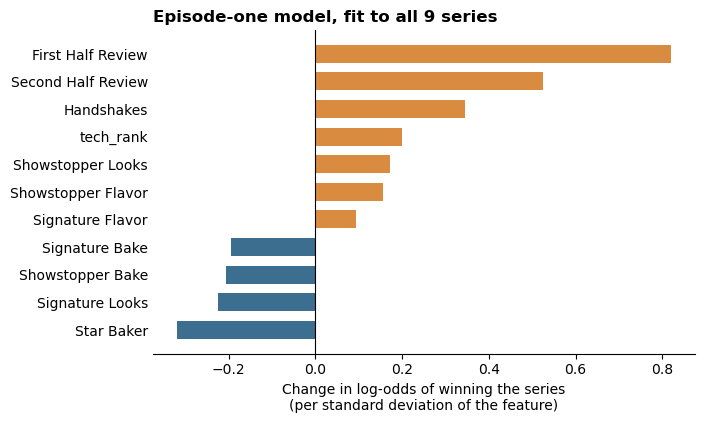

In [12]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0))
model.fit(ep1[features], ep1["won_series"])
coefs = pd.Series(model[-1].coef_[0], index=features).sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(coefs.index, coefs.values, color=[SCI_ORANGE if v > 0 else SCI for v in coefs.values], height=0.65)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in log-odds of winning the series\n(per standard deviation of the feature)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title("Episode-one model, fit to all 9 series", loc="left", fontweight="bold")
plt.show()

### Step 3: does it actually predict?
A fair test has to predict a series the model hasn't seen. **Leave-one-series-out**: fit on 8 series, predict the 9th, and repeat for each series. In every held-out series, rank the bakers by their predicted chance of winning and see where the real winner lands. With about 11 bakers per series, guessing at random puts the winner at rank 6 on average.

In [13]:
rows, probs = [], []
for s in ep1["Series"].unique():
    train, test = ep1[ep1["Series"] != s], ep1[ep1["Series"] == s].copy()
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(train[features], train["won_series"])
    test["p_win"] = m.predict_proba(test[features])[:, 1]
    test["rank"] = test["p_win"].rank(ascending=False, method="min").astype(int)
    probs.append(test)
    w = test[test["won_series"] == 1].iloc[0]
    rows.append(dict(series=s, winner=w["Contestant"], winner_rank=w["rank"], bakers=len(test),
                     model_favorite=test.sort_values("p_win").iloc[-1]["Contestant"]))
cv = pd.DataFrame(rows)
probs = pd.concat(probs)

# same check on the data the model was trained on, for comparison
ep1["p_in_sample"] = model.predict_proba(ep1[features])[:, 1]
in_rank = ep1.groupby("Series")["p_in_sample"].rank(ascending=False, method="min")[ep1["won_series"] == 1]

print(f"Winner's average rank, predicting unseen series: {cv['winner_rank'].mean():.1f} "
      f"(random guessing: {((cv['bakers'] + 1) / 2).mean():.1f}); ranked first in {(cv['winner_rank'] == 1).sum()} of 9")
print(f"Winner's average rank on the training data:      {in_rank.mean():.1f}")
cv

Winner's average rank, predicting unseen series: 7.3 (random guessing: 6.1); ranked first in 1 of 9
Winner's average rank on the training data:      3.7


,series,winner,winner_rank,bakers,model_favorite
0,5,Sophie,10,11,Liam
1,6,Rahul,9,11,Dan
2,7,David,11,12,Steph
3,8,Peter,9,11,Hermine
4,9,Giuseppe,1,11,Giuseppe
5,10,Syabira,8,11,Janusz
6,11,Matty,9,11,Cristy
7,12,Georgie,2,11,Illiyin
8,13,Jasmine,7,11,Nadia


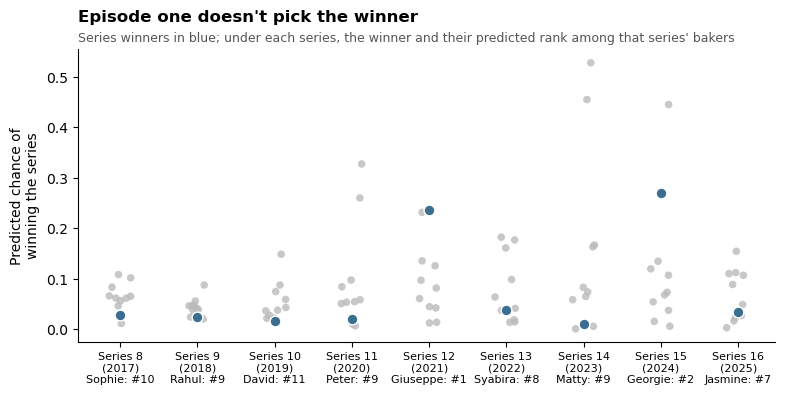

In [14]:
# Each dot is a baker's predicted chance of winning, from a model that never saw that series; winners in blue
fig, ax = plt.subplots(figsize=(9, 3.8))
series_label = {s: f"Series {s + 3}\n({s + 2012})" for s in probs["Series"].unique()}    # Netflix 5 = UK series 8 (2017)
x = probs["Series"].map({s: i for i, s in enumerate(series_label)})
jit = np.random.default_rng(1).uniform(-0.15, 0.15, len(probs))
others_p, winners_p = probs["won_series"] == 0, probs["won_series"] == 1
ax.scatter(x[others_p] + jit[others_p], probs.loc[others_p, "p_win"], s=30, color=MUTED, alpha=0.8, edgecolor="none")
ax.scatter(x[winners_p], probs.loc[winners_p, "p_win"], s=60, color=SCI, edgecolor="white", zorder=3)
ticks = [f"{series_label[r['series']]}\n{r['winner']}: #{r['winner_rank']}" for _, r in cv.iterrows()]
ax.set_xticks(range(len(ticks)), ticks, fontsize=8)
ax.set_ylabel("Predicted chance of\nwinning the series")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Episode one doesn't pick the winner", loc="left", fontweight="bold", pad=20)
ax.text(0, 1.025, "Series winners in blue; under each series, the winner and their predicted rank among that series' bakers",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.show()

### Step 4: checking the model's assumptions
Logistic regression does **not** assume normally distributed errors: the outcome is 0 or 1, so the residuals can't be normal, and a residual QQ plot isn't meaningful here. What it does assume:
1. **Enough events for the number of features.** A common rule of thumb is at least 10 events (here, winners) per feature.
2. **Features that aren't nearly redundant** (low multicollinearity), or the coefficients become unstable.
3. **Independent observations.** Two ways this could fail here: the series might not be comparable (different bakers, judges' moods, or a scorer who changed over time), and within a series the bakers are *not* independent, because exactly one of them wins.
4. **A linear effect on the log-odds** for numeric features like `tech_rank`. With 9 winners there's no way to check this, so we note it and move on.

In [15]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

# 1. events per feature
print(f"{ep1['won_series'].sum()} winners / {len(features)} features = "
      f"{ep1['won_series'].sum() / len(features):.1f} events per feature (rule of thumb: 10 or more)")

# 2. multicollinearity: variance inflation factor (1 = unrelated to the other features; above 5-10 is a concern)
X = sm.add_constant((ep1[features] - ep1[features].mean()) / ep1[features].std())
pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(features))], index=features, name="VIF").round(2)

9 winners / 11 features = 0.8 events per feature (rule of thumb: 10 or more)


Signature Bake        1.55
Signature Flavor      1.30
Signature Looks       1.28
Handshakes            1.13
tech_rank             1.49
First Half Review     2.38
Showstopper Bake      1.31
Showstopper Flavor    1.23
Showstopper Looks     1.36
Second Half Review    3.35
Star Baker            1.31
Name: VIF, dtype: float64

In [16]:
from scipy.stats import kruskal, chi2_contingency

# 3a. Are the series comparable? Episode-one averages by series, and a Kruskal-Wallis test of each feature across series
by_series = ep1.groupby("Series")[features].mean().round(2)
by_series.index = [f"Series {s + 3}" for s in by_series.index]
by_series.loc["p (differs by series)"] = [kruskal(*[g[f].values for _, g in ep1.groupby("Series")]).pvalue
                                         if ep1[f].nunique() > 1 else np.nan for f in features]
by_series.round(2)

,Signature Bake,Signature Flavor,Signature Looks,Handshakes,tech_rank,First Half Review,Showstopper Bake,Showstopper Flavor,Showstopper Looks,Second Half Review,Star Baker
Series 8,0.00,0.09,0.18,0.18,0.47,0.00,0.00,0.82,0.18,0.09,0.09
Series 9,0.00,0.55,0.36,0.00,0.46,0.00,0.45,0.36,0.64,0.00,0.09
Series 10,0.42,0.50,0.42,0.00,0.49,0.00,0.25,0.33,0.50,0.08,0.08
Series 11,0.36,0.27,0.45,0.00,0.47,0.09,0.36,0.82,0.64,0.09,0.09
Series 12,0.18,0.55,-0.18,0.00,0.51,0.09,0.45,0.64,0.09,0.00,0.09
Series 13,0.45,0.82,0.09,0.00,0.48,0.18,0.45,0.45,0.18,0.09,0.09
Series 14,0.45,0.82,0.36,0.00,0.54,0.18,0.45,0.55,0.45,0.18,0.09
Series 15,0.09,0.73,0.18,0.09,0.50,-0.09,0.36,0.82,0.64,0.09,0.09
Series 16,-0.18,0.82,0.36,0.00,0.47,0.00,0.09,0.82,0.18,0.09,0.09
p (differs by series),0.58,0.08,0.72,0.13,1.00,0.95,0.89,0.49,0.57,1.00,1.00


In [17]:
# 3a (continued). Episode one alone is small (about 11 bakers per series), so also check every week: does the mix of
# praised / mixed / criticized scores differ by series? A drift here could mean the scorer or the show changed over time.
scores = ["Signature Bake", "Signature Flavor", "Signature Looks", "Showstopper Bake", "Showstopper Flavor", "Showstopper Looks"]
pd.DataFrame({"p (chi-square, score mix differs by series)": [chi2_contingency(pd.crosstab(weeks["Series"], weeks[f]))[1] for f in scores]},
             index=scores).round(3)

,"p (chi-square, score mix differs by series)"
Signature Bake,0.003
Signature Flavor,0.217
Signature Looks,0.424
Showstopper Bake,0.403
Showstopper Flavor,0.200
Showstopper Looks,0.366


In [18]:
from statsmodels.discrete.conditional_models import ConditionalLogit

# 3b. Exactly one winner per series. A conditional logit model builds that in: it compares bakers only *within* a series
# ("which of these 11 bakers wins?"), so differences between series drop out entirely.
cl = ConditionalLogit(ep1["won_series"], ep1[features], groups=ep1["Series"]).fit(disp=0)
pd.DataFrame({"coef": cl.params, "std err": cl.bse, "p": cl.pvalues}).round(3)

,coef,std err,p
Signature Bake,-0.378,0.654,0.563
Signature Flavor,0.113,0.688,0.869
Signature Looks,-0.445,0.516,0.388
Handshakes,2.950,2.065,0.153
tech_rank,1.377,1.693,0.416
First Half Review,2.225,1.363,0.103
Showstopper Bake,-0.289,0.506,0.568
Showstopper Flavor,0.198,0.680,0.771
Showstopper Looks,0.059,0.603,0.922
Second Half Review,0.987,1.152,0.391


**What the checks show.**
- **Too few events.** 9 winners for 11 features is under 1 event per feature, far below the rule of thumb. This alone explains why the coefficients look like a story but don't hold up on new series.
- **Multicollinearity is not the problem.** All VIFs are low (the first- and second-half reviews are the most related, at about 2-3).
- **Series are mostly comparable.** No episode-one feature differs detectably across series, though with about 11 bakers per series that test has little power. Across all weeks, only the signature *bake* score's mix differs by series (p ≈ 0.003); the other five scores don't. That's worth remembering if we use signature bake scores later.
- **Accounting for one winner per series doesn't rescue the model.** The conditional logit, which only compares bakers within the same series, finds no feature with a reliable effect (every p > 0.1).

So the honest conclusion for episode one is "not enough information," not "these features don't matter." The next step, adding episodes, also helps with the events problem only if we keep the number of features small (for example, summarize each episode as a few numbers rather than adding 11 new features per week).

Handshakes           -0.364856
tech_rank            -0.351315
Signature Looks      -0.267021
Star Baker           -0.186515
Signature Bake       -0.143882
Showstopper Bake      0.024817
Showstopper Looks     0.310874
Showstopper Flavor    0.443113
Signature Flavor      0.570601
First Half Review     0.618440
Second Half Review    0.777909
dtype: float64


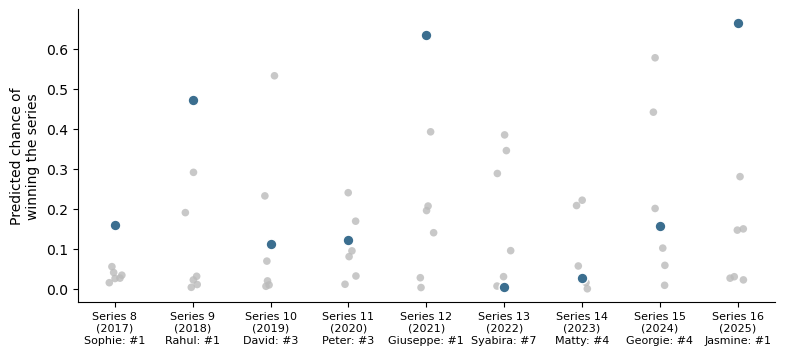

In [19]:
episodes = [1,2,3,4,5]
ep1,features = grab_episodes(episodes)
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0))
model.fit(ep1[features], ep1["won_series"])
coefs = pd.Series(model[-1].coef_[0], index=features).sort_values()
print(coefs)

rows, probs = [], []
for s in ep1["Series"].unique():
    train, test = ep1[ep1["Series"] != s], ep1[ep1["Series"] == s].copy()
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(train[features], train["won_series"])
    test["p_win"] = m.predict_proba(test[features])[:, 1]
    test["rank"] = test["p_win"].rank(ascending=False, method="min").astype(int)
    probs.append(test)
    w = test[test["won_series"] == 1].iloc[0]
    rows.append(dict(series=s, winner=w["Contestant"], winner_rank=w["rank"], bakers=len(test),
                     model_favorite=test.sort_values("p_win").iloc[-1]["Contestant"]))
cv = pd.DataFrame(rows)
probs = pd.concat(probs)


# Each dot is a baker's predicted chance of winning, from a model that never saw that series; winners in blue
fig, ax = plt.subplots(figsize=(9, 3.8))
series_label = {s: f"Series {s + 3}\n({s + 2012})" for s in probs["Series"].unique()}    # Netflix 5 = UK series 8 (2017)
x = probs["Series"].map({s: i for i, s in enumerate(series_label)})
jit = np.random.default_rng(1).uniform(-0.1, 0.1, len(probs))
others_p, winners_p = probs["won_series"] == 0, probs["won_series"] == 1
ax.scatter(x[others_p] + jit[others_p], probs.loc[others_p, "p_win"], s=30, color=MUTED, alpha=0.8, edgecolor="none")
ax.scatter(x[winners_p], probs.loc[winners_p, "p_win"], s=60, color=SCI, edgecolor="white", zorder=3)
ticks = [f"{series_label[r['series']]}\n{r['winner']}: #{r['winner_rank']}" for _, r in cv.iterrows()]
ax.set_xticks(range(len(ticks)), ticks, fontsize=8)
ax.set_ylabel("Predicted chance of\nwinning the series")
ax.spines[["top", "right"]].set_visible(False)

plt.show()


### How early can we pick the winner?
Repeat the leave-one-series-out test using episodes 1 through *k*, for every *k* up to the semifinal. Fewer bakers are left each week, so guessing also gets better; the question is whether the model stays ahead of guessing.

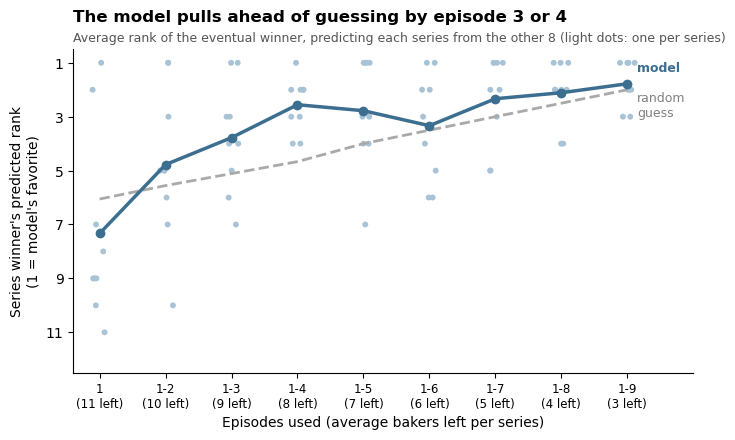

,bakers,winner_rank,guess_rank
episodes,,,
1,11.1,7.3,6.1
2,10.1,4.8,5.6
3,9.2,3.8,5.1
4,8.3,2.6,4.7
5,7.0,2.8,4.0
6,6.0,3.3,3.5
7,5.0,2.3,3.0
8,4.0,2.1,2.5
9,3.0,1.8,2.0


In [20]:
import contextlib, io

sweep = []
for k in range(1, 10):
    with contextlib.redirect_stdout(io.StringIO()):            # quiet grab_episodes' printout
        ep_k, feats_k = grab_episodes(list(range(1, k + 1)))
    for s in ep_k["Series"].unique():
        train, test = ep_k[ep_k["Series"] != s], ep_k[ep_k["Series"] == s]
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(train[feats_k], train["won_series"])
        p = m.predict_proba(test[feats_k])[:, 1]
        p_winner = p[test["won_series"].values == 1][0]
        sweep.append(dict(episodes=k, series=s, bakers=len(test),
                          winner_rank=int((p > p_winner).sum() + 1), guess_rank=(len(test) + 1) / 2))
sweep = pd.DataFrame(sweep)
summary = sweep.groupby("episodes")[["bakers", "winner_rank", "guess_rank"]].mean()

fig, ax = plt.subplots(figsize=(8, 4.2))
jit = np.random.default_rng(2).uniform(-0.12, 0.12, len(sweep))
ax.scatter(sweep["episodes"] + jit, sweep["winner_rank"], s=18, color=SCI_LIGHT, edgecolor="none", zorder=1)
ax.plot(summary.index, summary["guess_rank"], color="darkgrey", lw=2, ls="--", zorder=2)
ax.plot(summary.index, summary["winner_rank"], color=SCI, lw=2.5, marker="o", zorder=3)
ax.text(9.15, summary.loc[9, "guess_rank"] + 0.6, "random\nguess", color="grey", fontsize=9, va="center")   # y axis is flipped:
ax.text(9.15, summary.loc[9, "winner_rank"] - 0.6, "model", color=SCI, fontsize=9, fontweight="bold", va="center")  # + is lower

ax.set_xticks(range(1, 10), [f"1-{k}\n({summary.loc[k, 'bakers']:.0f} left)" if k > 1 else "1\n(11 left)" for k in range(1, 10)],
              fontsize=8.5)
ax.set_xlabel("Episodes used (average bakers left per series)")
ax.set_ylabel("Series winner's predicted rank\n(1 = model's favorite)")
ax.set_ylim(12.5, 0.5)                                           # rank 1 at the top
ax.set_yticks([1, 3, 5, 7, 9, 11])
ax.set_xlim(0.6, 10)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("The model pulls ahead of guessing by episode 3 or 4", loc="left", fontweight="bold", pad=20)
ax.text(0, 1.025, "Average rank of the eventual winner, predicting each series from the other 8 (light dots: one per series)",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.show()

summary.round(1)

### More ways to summarize the episodes, then let regularization choose
Averaging hides *when* things happened. `grab_episodes_rich` gives each baker four kinds of summary over the episodes used:
- **avg:** the plain average (or total, for handshakes and Star Baker), as before,
- **recent-weighted:** an average with weights 1, 2, 3, ..., so later weeks count more,
- **last ep:** the baker's most recent episode on its own (a few bakers missed a week through illness, so it's *their* most recent),
- **trend:** one number per baker, the slope of their overall bake score (the average of the six bake scores) across the episodes.

That's 32 features for 9 winners, so we use **L1 (lasso) regularization**, which shrinks the coefficients of unhelpful features to exactly zero. How hard to shrink is chosen by leave-one-series-out cross-validation *inside* the training series, so the series being predicted never helps pick the features.

In [21]:
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import LeaveOneGroupOut

scored = ["Signature Bake", "Signature Flavor", "Signature Looks", "tech_rank", "First Half Review",
          "Showstopper Bake", "Showstopper Flavor", "Showstopper Looks", "Second Half Review"]
bake_scores = ["Signature Bake", "Signature Flavor", "Signature Looks", "Showstopper Bake", "Showstopper Flavor", "Showstopper Looks"]

def grab_episodes_rich(episodes):
    """Like grab_episodes, but four summaries of each baker's episodes: the average, a recent-weighted average,
    the most recent episode alone, and one trend (is their overall bake score going up or down?)."""
    eps = judging[judging["Round"].isin(episodes)].copy()
    gone = set(zip(eps.loc[eps["eliminated"] == 1, "Series"], eps.loc[eps["eliminated"] == 1, "Contestant"]))
    eps = eps[[(s, c) not in gone for s, c in zip(eps["Series"], eps["Contestant"])]]
    eps["tech_rank"] = (eps["Tech"] - 1) / (eps["bakers"] - 1)
    for col in ["Signature Handshake", "Showstopper Handshake", "First Half Review", "Second Half Review", "Winner"]:
        eps[col] = eps[col].fillna(0)
    eps["Handshakes"] = eps["Signature Handshake"] + eps["Showstopper Handshake"]
    eps["Star Baker"] = eps["Winner"]
    eps["overall"] = eps[bake_scores].mean(axis=1)                 # one overall bake score per baker-week
    eps["w"] = eps["Round"] - min(episodes) + 1                    # weights 1, 2, 3, ...: later weeks count more

    def summarize(g):
        g = g.sort_values("Round")
        latest = g.iloc[-1]                                        # their most recent episode (a few bakers missed a week)
        out = {}
        for f in scored:
            out[f"avg: {f}"] = g[f].mean()
            out[f"recent-weighted: {f}"] = np.average(g[f], weights=g["w"])
            out[f"last ep: {f}"] = latest[f]
        for f in ["Handshakes", "Star Baker"]:
            out[f"total: {f}"] = g[f].sum()
            out[f"last ep: {f}"] = latest[f]
        out["trend: overall bake score"] = np.polyfit(g["Round"], g["overall"], 1)[0] if len(g) > 1 else 0.0
        return pd.Series(out)

    ep = eps.groupby(["Series", "Contestant"]).apply(summarize).reset_index()
    ep["won_series"] = [int((s, c) in champions) for s, c in zip(ep["Series"], ep["Contestant"])]
    features = [c for c in ep.columns if c not in ("Series", "Contestant", "won_series")]
    return ep, features

def lasso_model(train):
    """L1-regularized logistic regression; the penalty strength is picked by leave-one-series-out CV *inside* the
    training series, so the held-out series never influences which features are kept."""
    inner = list(LeaveOneGroupOut().split(train, groups=train["Series"]))
    return make_pipeline(StandardScaler(), LogisticRegressionCV(
        Cs=np.logspace(-2, 1, 12), penalty="l1", solver="liblinear", cv=inner, scoring="neg_log_loss"))

/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



/var/folders/43/f8z3kwjs27j1ztlt_wxk3q140000gp/T/ipykernel_61369/2392792584.py:36: FutureWarning:

DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.



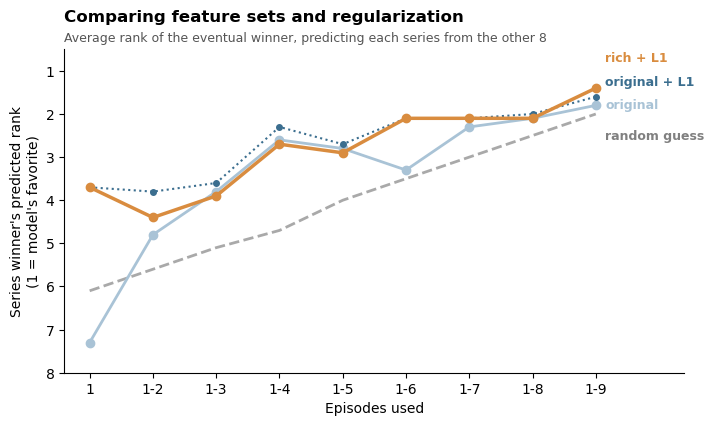

model,original,original + L1,rich + L1,random guess
episodes,,,,
1,7.3,3.7,3.7,6.1
2,4.8,3.8,4.4,5.6
3,3.8,3.6,3.9,5.1
4,2.6,2.3,2.7,4.7
5,2.8,2.7,2.9,4.0
6,3.3,2.1,2.1,3.5
7,2.3,2.1,2.1,3.0
8,2.1,2.0,2.1,2.5
9,1.8,1.6,1.4,2.0


In [22]:
# Compare three models on the same leave-one-series-out test, for episodes 1-k:
#   original:        the 11 averaged/summed features, light L2 regularization (the model above)
#   original + L1:   the same 11 features, with lasso choosing which to keep
#   rich + L1:       all 32 features, with lasso choosing which to keep
results, picked = [], []
for k in range(1, 10):
    with contextlib.redirect_stdout(io.StringIO()):
        ep_a, feats_a = grab_episodes(list(range(1, k + 1)))
    ep_r, feats_r = grab_episodes_rich(list(range(1, k + 1)))
    for s in ep_r["Series"].unique():
        for name, ep_k, feats_k, make in [("original", ep_a, feats_a, lambda tr: make_pipeline(StandardScaler(), LogisticRegression(C=1.0))),
                                          ("original + L1", ep_a, feats_a, lasso_model),
                                          ("rich + L1", ep_r, feats_r, lasso_model)]:
            train, test = ep_k[ep_k["Series"] != s], ep_k[ep_k["Series"] == s]
            m = make(train).fit(train[feats_k], train["won_series"])
            p = m.predict_proba(test[feats_k])[:, 1]
            p_winner = p[test["won_series"].values == 1][0]
            results.append(dict(model=name, episodes=k, series=s, winner_rank=int((p > p_winner).sum() + 1),
                                guess_rank=(len(test) + 1) / 2))
            if name == "rich + L1":
                picked.append(pd.Series(m[-1].coef_[0] != 0, index=feats_k, name=(k, s)))
results = pd.DataFrame(results)
picked = pd.DataFrame(picked)

table = results.pivot_table(index="episodes", columns="model", values="winner_rank").round(1)
table["random guess"] = results.groupby("episodes")["guess_rank"].mean().round(1)

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(table.index, table["random guess"], color="darkgrey", lw=2, ls="--")
ax.plot(table.index, table["original"], color=SCI_LIGHT, lw=2, marker="o")
ax.plot(table.index, table["original + L1"], color=SCI, lw=1.5, ls=":", marker="o", ms=4)
ax.plot(table.index, table["rich + L1"], color=SCI_ORANGE, lw=2.5, marker="o")
for col, c, dy in [("random guess", "grey", 0.5), ("original", SCI_LIGHT, 0.0), ("original + L1", SCI, -0.35), ("rich + L1", SCI_ORANGE, -0.7)]:
    ax.text(9.15, table.loc[9, col] + dy, col, color=c, fontsize=9, fontweight="bold", va="center")
ax.set_xticks(range(1, 10), ["1"] + [f"1-{k}" for k in range(2, 10)])
ax.set_xlabel("Episodes used")
ax.set_ylabel("Series winner's predicted rank\n(1 = model's favorite)")
ax.set_ylim(8, 0.5)
ax.set_xlim(0.6, 10.4)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Comparing feature sets and regularization", loc="left", fontweight="bold", pad=20)
ax.text(0, 1.025, "Average rank of the eventual winner, predicting each series from the other 8",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.show()

table

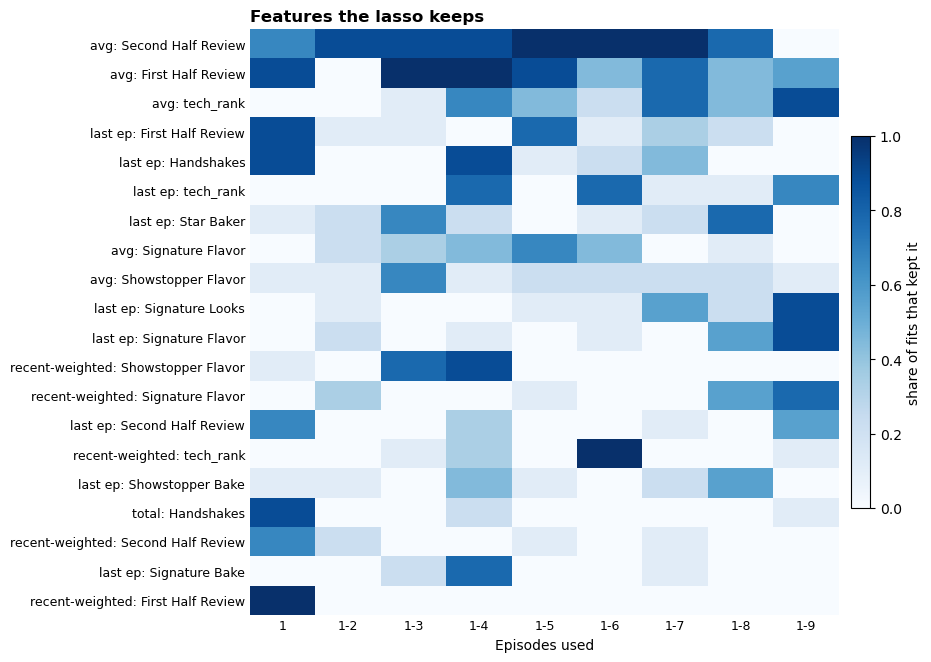

In [23]:
# Which of the 32 features does the lasso keep? Share of the 9 held-out fits that kept each feature, by episodes used.
# Only features kept at least half the time somewhere are shown.
keep = picked.groupby(level=0).mean().T                                 # rows: features, columns: episodes used
keep = keep[(keep >= 0.5).any(axis=1)]
keep = keep.loc[keep.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8, 0.32 * len(keep) + 1.2))
im = ax.imshow(keep.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_yticks(range(len(keep)), keep.index, fontsize=9)
ax.set_xticks(range(keep.shape[1]), ["1"] + [f"1-{k}" for k in range(2, 10)], fontsize=9)
ax.set_xlabel("Episodes used")
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="share of fits that kept it")
ax.set_title("Features the lasso keeps", loc="left", fontweight="bold")
plt.show()

**What this shows.**
- **The regularization helps; the extra features don't.** The original 11 features with the lasso (dotted line) do as well as or better than all 32 features at almost every step. The biggest gain is at episode one (rank 7.3 → 3.7): there the lasso throws out the noisy features that made the original model worse than guessing.
- **Recency and trend add little.** The trend feature is never kept. "Last ep" and "recent-weighted" versions get picked now and then, but not consistently. (At episode one, the average, recent-weighted, and last-episode versions are identical copies, so which one gets kept there is arbitrary.)
- **What the judges *say* matters most.** The features kept most often are the average first- and second-half reviews, followed by technical rank later in the series. The bake scores themselves are rarely kept.
- **The chosen features jump around from one step to the next.** With 9 winners, which features win out is unstable, so the heatmap is a hint about what matters, not a finding.


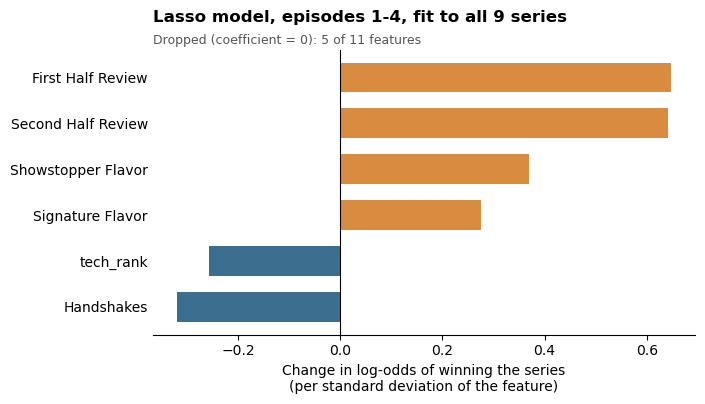

Penalty chosen: C = 0.811
Dropped: Signature Bake, Signature Looks, Showstopper Bake, Showstopper Looks, Star Baker


In [24]:
episodes = [1,2,3,4]
ep4, features = grab_episodes(episodes)          # or grab_episodes_rich(episodes) for all 32 features
model = lasso_model(ep4)                          # L1; penalty chosen by leave-one-series-out CV
model.fit(ep4[features], ep4["won_series"])
coefs = pd.Series(model[-1].coef_[0], index=features)
kept, dropped = coefs[coefs != 0].sort_values(), coefs[coefs == 0].index.tolist()

fig, ax = plt.subplots(figsize=(7, 0.35 * len(kept) + 1.6))
ax.barh(kept.index, kept.values, color=[SCI_ORANGE if v > 0 else SCI for v in kept.values], height=0.65)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in log-odds of winning the series\n(per standard deviation of the feature)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_title(f"Lasso model, episodes {min(episodes)}-{max(episodes)}, fit to all 9 series",
             loc="left", fontweight="bold", pad=20)
ax.text(0, 1.02, f"Dropped (coefficient = 0): {len(dropped)} of {len(features)} features",
        transform=ax.transAxes, fontsize=9, color="#555555")
plt.show()

print("Penalty chosen: C =", round(model[-1].C_[0], 3))
print("Dropped:", ", ".join(dropped))

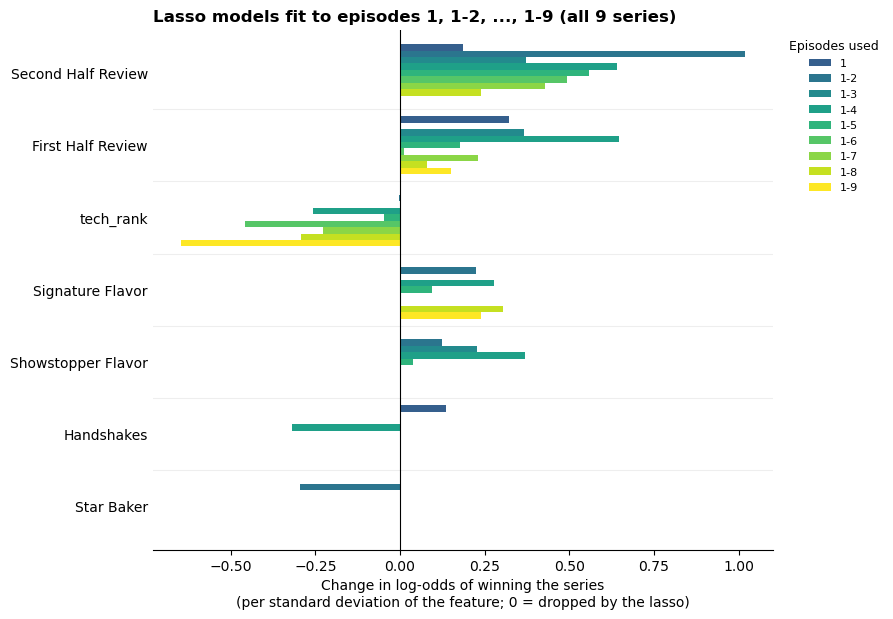

,1,2,3,4,5,6,7,8,9
Star Baker,0.00,-0.30,0.00,0.00,0.00,0.00,0.00,0.00,0.00
Handshakes,0.14,0.00,0.00,-0.32,0.00,0.00,0.00,0.00,0.00
Showstopper Flavor,0.00,0.12,0.23,0.37,0.04,0.00,0.00,0.00,0.00
Signature Flavor,0.00,0.22,0.00,0.28,0.09,0.00,0.00,0.30,0.24
tech_rank,0.00,-0.00,0.00,-0.26,-0.05,-0.46,-0.23,-0.29,-0.65
First Half Review,0.32,0.00,0.37,0.65,0.18,0.01,0.23,0.08,0.15
Second Half Review,0.18,1.02,0.37,0.64,0.56,0.49,0.43,0.24,0.00


In [25]:
# Lasso coefficients for every set of episodes, grouped by feature
coef_by_k = {}
for k in range(1, 10):
    with contextlib.redirect_stdout(io.StringIO()):
        ep_k, feats_k = grab_episodes(list(range(1, k + 1)))
    m = lasso_model(ep_k).fit(ep_k[feats_k], ep_k["won_series"])
    coef_by_k[k] = pd.Series(m[-1].coef_[0], index=feats_k)
coef_by_k = pd.DataFrame(coef_by_k)                                # rows: features, columns: episodes used
coef_by_k = coef_by_k[(coef_by_k != 0).any(axis=1)]               # drop features the lasso never keeps
coef_by_k = coef_by_k.loc[coef_by_k.abs().mean(axis=1).sort_values().index]   # biggest effects at the top

ks = coef_by_k.columns
shades = plt.cm.viridis(np.linspace(0.3, 1, len(ks)))                # light = episode 1 only, dark = episodes 1-9
bar_h = 0.8 / len(ks)

fig, ax = plt.subplots(figsize=(8, 0.75 * len(coef_by_k) + 1.5))
for j, k in enumerate(ks):
    y = np.arange(len(coef_by_k)) + 0.4 - (j + 0.5) * bar_h          # episode 1 on top within each feature
    ax.barh(y, coef_by_k[k], height=bar_h, color=shades[j], label="1" if k == 1 else f"1-{k}")
ax.set_yticks(range(len(coef_by_k)), coef_by_k.index)
for y in np.arange(len(coef_by_k) - 1) + 0.5:                      # thin lines between features
    ax.axhline(y, color="#eeeeee", lw=0.8, zorder=0)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in log-odds of winning the series\n(per standard deviation of the feature; 0 = dropped by the lasso)")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.tick_params(axis="y", length=0)
ax.set_ylim(-0.6, len(coef_by_k) - 0.4)
ax.legend(title="Episodes used", fontsize=8, title_fontsize=9, frameon=False,
          loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("Lasso models fit to episodes 1, 1-2, ..., 1-9 (all 9 series)", loc="left", fontweight="bold")
plt.show()


coef_by_k.round(2)

## Part 6: Does winning a particular week predict winning the series?
Every series has a few core weeks (Cake, Biscuits, Bread, Pastry, Desserts, and the Pâtisserie semifinal), and some series add Chocolate or Caramel. The rest are one-off themes (Italian, Vegan, The '80s, ...). The theme for each episode comes from the episode titles on each series' Wikipedia page; Puddings week (series 8) is counted as Desserts.

In [26]:
# Week themes, from the episode titles on each series' Wikipedia page (UK series 8-16)
episode_titles = {
    8:  ["Cakes", "Biscuits", "Bread", "Caramel", "Puddings", "Pastry", "Italian", "Forgotten Bakes", "Pâtisserie", "Final"],
    9:  ["Biscuits", "Cakes", "Bread", "Desserts", "Spice", "Pastry", "Vegan", "Danish", "Pâtisserie", "Final"],
    10: ["Cake", "Biscuits", "Bread", "Dairy", "The Roaring Twenties", "Desserts", "Festivals", "Pastry", "Pâtisserie", "Final"],
    11: ["Cake", "Biscuits", "Bread", "Chocolate", "Pastry", "Japanese", "The '80s", "Desserts", "Pâtisserie", "Final"],
    12: ["Cake", "Biscuits", "Bread", "Desserts", "German", "Pastry", "Caramel", "Free-from", "Pâtisserie", "Final"],
    13: ["Cake", "Biscuits", "Bread", "Mexican", "Desserts", "Halloween", "Custard", "Pastry", "Pâtisserie", "Final"],
    14: ["Cake", "Biscuits", "Bread", "Chocolate", "Pastry", "Botanical", "Desserts", "Party", "Pâtisserie", "Final"],
    15: ["Cake", "Biscuits", "Bread", "Caramel", "Pastry", "Autumn", "Desserts", "The '70s", "Pâtisserie", "Final"],
    16: ["Cake", "Biscuits", "Bread", "Back To School", "Chocolate", "Pastry", "Meringue", "Desserts", "Pâtisserie", "Final"],
}
core = {"Cake": "Cake", "Cakes": "Cake", "Biscuits": "Biscuits", "Bread": "Bread", "Pastry": "Pastry",
        "Desserts": "Desserts", "Puddings": "Desserts", "Chocolate": "Chocolate", "Caramel": "Caramel",
        "Pâtisserie": "Pâtisserie", "Final": "Final"}          # everything else is a one-off theme
themes = pd.DataFrame([dict(Series=uk - 3, Round=i + 1, title=t, theme=core.get(t, "One-off theme"))
                       for uk, titles in episode_titles.items() for i, t in enumerate(titles)])   # Netflix numbering = UK - 3
judging = judging.drop(columns=["title", "theme"], errors="ignore").merge(themes, on=["Series", "Round"], how="left")
themes.pivot(index="Round", columns="Series", values="title").rename(columns=lambda s: f"UK {s + 3}")

Series,UK 8,UK 9,UK 10,UK 11,UK 12,UK 13,UK 14,UK 15,UK 16
Round,,,,,,,,,
1,Cakes,Biscuits,Cake,Cake,Cake,Cake,Cake,Cake,Cake
2,Biscuits,Cakes,Biscuits,Biscuits,Biscuits,Biscuits,Biscuits,Biscuits,Biscuits
3,Bread,Bread,Bread,Bread,Bread,Bread,Bread,Bread,Bread
4,Caramel,Desserts,Dairy,Chocolate,Desserts,Mexican,Chocolate,Caramel,Back To School
5,Puddings,Spice,The Roaring Twenties,Pastry,German,Desserts,Pastry,Pastry,Chocolate
6,Pastry,Pastry,Desserts,Japanese,Pastry,Halloween,Botanical,Autumn,Pastry
7,Italian,Vegan,Festivals,The '80s,Caramel,Custard,Desserts,Desserts,Meringue
8,Forgotten Bakes,Danish,Pastry,Desserts,Free-from,Pastry,Party,The '70s,Desserts
9,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie,Pâtisserie


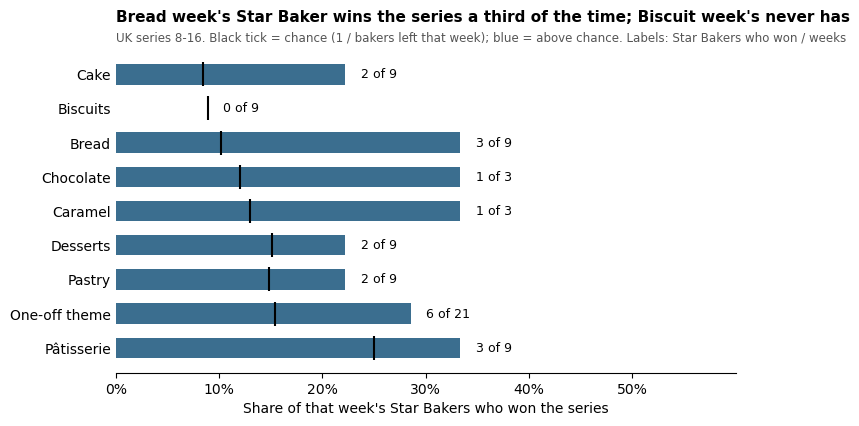

,weeks,star_baker_won,share,chance
theme,,,,
Cake,9,2,0.22,0.08
Biscuits,9,0,0.00,0.09
Bread,9,3,0.33,0.10
Chocolate,3,1,0.33,0.12
Caramel,3,1,0.33,0.13
Desserts,9,2,0.22,0.15
Pastry,9,2,0.22,0.15
One-off theme,21,6,0.29,0.15
Pâtisserie,9,3,0.33,0.25


In [27]:
# For each theme: how often did that week's Star Baker go on to win the series?
# Chance comparison: if the Star Baker were no more likely to win than anyone else left that week, they'd win the
# series about 1 / (bakers left) of the time.
sb = judging[(judging["Winner"] == 1) & (judging["theme"] != "Final")].copy()
sb["won_series"] = [(s, c) in champions for s, c in zip(sb["Series"], sb["Contestant"])]
by_theme = sb.groupby("theme").agg(weeks=("won_series", "size"), star_baker_won=("won_series", "sum"),
                                   share=("won_series", "mean"), chance=("bakers", lambda b: (1 / b).mean()))
order_t = ["Cake", "Biscuits", "Bread", "Chocolate", "Caramel", "Desserts", "Pastry", "One-off theme", "Pâtisserie"]
by_theme = by_theme.loc[order_t]

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(by_theme))[::-1]
ax.barh(y, by_theme["share"], color=[SCI if s > c else MUTED for s, c in zip(by_theme["share"], by_theme["chance"])], height=0.6)
ax.scatter(by_theme["chance"], y, marker="|", s=300, color="black", zorder=3)
for yi, (t, r) in zip(y, by_theme.iterrows()):
    ax.text(max(r["share"], r["chance"]) + 0.015, yi, f"{r['star_baker_won']:.0f} of {r['weeks']:.0f}", va="center", fontsize=9)
ax.set_yticks(y, by_theme.index)
ax.tick_params(axis="y", length=0)
ax.set_xlim(0, 0.6)
ax.set_xticks([0, 0.1, 0.2, 0.3, 0.4, 0.5], ["0%", "10%", "20%", "30%", "40%", "50%"])
ax.set_xlabel("Share of that week's Star Bakers who won the series")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.set_title("Bread week's Star Baker wins the series a third of the time; Biscuit week's never has",
             loc="left", fontweight="bold", fontsize=11, pad=20)
ax.text(0, 1.025, "UK series 8-16. Black tick = chance (1 / bakers left that week); blue = above chance. Labels: Star Bakers who won / weeks",
        transform=ax.transAxes, fontsize=8.5, color="#555555")
plt.show()

by_theme.round(2)

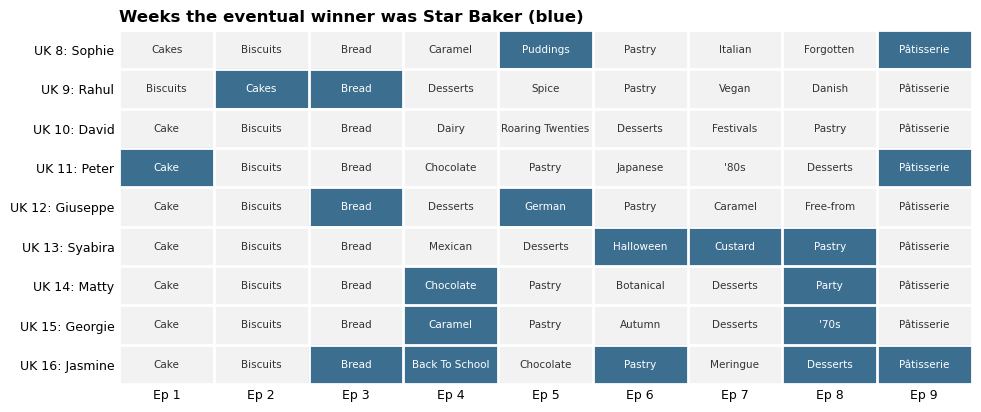

In [28]:
# When did each eventual winner win a week? One row per series; blue = the series winner was Star Baker that week
grid = themes[themes["Round"] <= 9].pivot(index="Series", columns="Round", values="title")
won_week = judging[(judging["Winner"] == 1) & (judging["Round"] <= 9)]
won_week = won_week[[(s, c) in champions for s, c in zip(won_week["Series"], won_week["Contestant"])]]
hit = pd.DataFrame(0, index=grid.index, columns=grid.columns)
for s, r in zip(won_week["Series"], won_week["Round"]):
    hit.loc[s, r] = 1
winner_name = {s: c for s, c in champions}

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.imshow(hit.values, cmap=plt.matplotlib.colors.ListedColormap(["#f2f2f2", SCI]), aspect="auto")
for i, s in enumerate(grid.index):
    for j, r in enumerate(grid.columns):
        ax.text(j, i, grid.loc[s, r].replace("The ", "").replace("Forgotten Bakes", "Forgotten"), ha="center", va="center",
                fontsize=7.5, color="white" if hit.loc[s, r] else "#333333")
ax.set_xticks(range(9), [f"Ep {r}" for r in grid.columns], fontsize=9)
ax.set_yticks(range(len(grid)), [f"UK {s + 3}: {winner_name[s]}" for s in grid.index], fontsize=9)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_xticks(np.arange(-0.5, 9), minor=True)
ax.set_yticks(np.arange(-0.5, len(grid)), minor=True)
ax.grid(which="minor", color="white", lw=2)
ax.tick_params(which="minor", length=0)
ax.set_title("Weeks the eventual winner was Star Baker (blue)", loc="left", fontweight="bold")
plt.show()

**What this shows.** No single week reliably picks the winner. Chocolate week has only happened 3 times, and its Star Baker won once (Matty, 2023). Bread week does best among the weeks every series has: its Star Baker won 3 of 9 series, about three times chance. Biscuit week's Star Baker has never won. The Pâtisserie semifinal looks good (3 of 9) but is about what chance predicts with only 4 bakers left. With 9 series, a difference of one or two winners moves these shares by 10-20 points, so these are hints, not rules. The grid also shows how varied winners are: David (2019) won without a single Star Baker, while Jasmine (2025) won five weeks.